# Reconocimiento Facial con Redes Neuronales Siamesas

**Estudiante:** Joan Schneider Beltrán Delgado
**Asignatura:** Deep Learning – Conceptos, CADI, Universidad de Cundinamarca
**Actividad:** R2-A1-S10 Redes Neuronales V

Este notebook implementa una **red neuronal siamesa** entrenada con **Triplet Loss** para reconocimiento facial, usando TensorFlow y Keras.

**Nota sobre el dataset:** la actividad permite usar imágenes propias o de personas con consentimiento explícito. En este caso se utilizó el dataset público **LFW (Labeled Faces in the Wild)**, recopilado específicamente para investigación académica en reconocimiento facial (Huang et al., 2007) y disponible directamente en `scikit-learn`, lo que evita cualquier inconveniente de consentimiento al tratarse de imágenes ya publicadas con fines de investigación.

## 1. Configuración del entorno

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

I0000 00:00:1793540317.886869   18648 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793540317.919774   18648 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793540318.784934   18648 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.22.0-rc0


## 2. Carga del dataset LFW

Se filtran solo las personas con al menos 20 fotos, para poder construir tripletas (ancla, positivo, negativo) con suficientes ejemplos por clase.

In [2]:
lfw = fetch_lfw_people(min_faces_per_person=20, resize=0.5, color=False)

X = lfw.images
y = lfw.target
nombres = lfw.target_names

print("Forma de las imágenes:", X.shape)
print("Número de personas (clases):", len(nombres))
print("Total de imágenes:", len(X))

ALTO, ANCHO = X.shape[1], X.shape[2]

Forma de las imágenes: (3023, 62, 47)
Número de personas (clases): 62
Total de imágenes: 3023


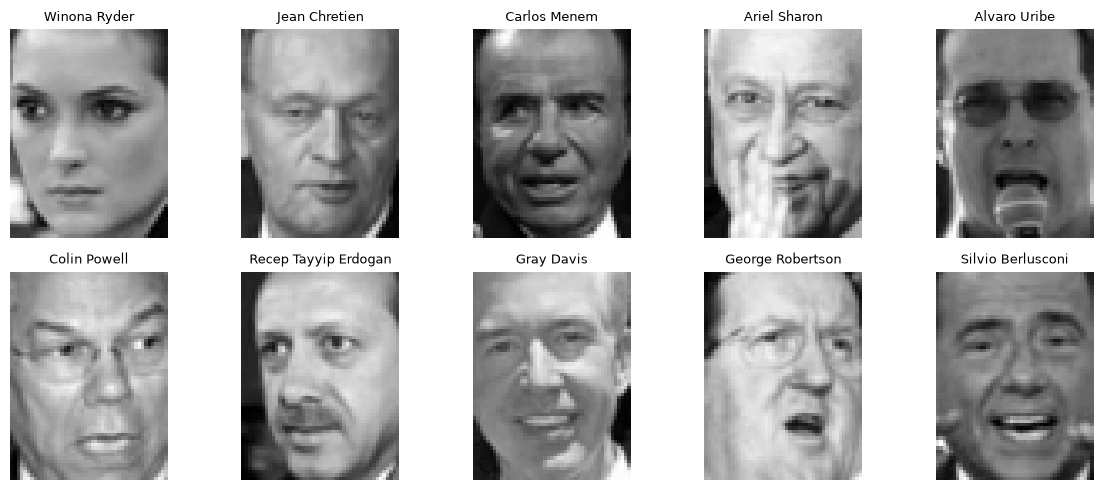

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i], cmap="gray")
    ax.set_title(nombres[y[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Preprocesamiento

Normalización de píxeles a [0, 1] y adición del canal de color (escala de grises), más la división en entrenamiento y prueba.

In [4]:
X = X.astype("float32") / 255.0
X = np.expand_dims(X, axis=-1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))

Entrenamiento: 2418 | Prueba: 605


## 4. Generación de tripletas (ancla, positivo, negativo)

Cada tripleta combina dos fotos de la misma persona (ancla y positivo) con una foto de una persona distinta (negativo).

In [5]:
def construir_indices_por_clase(y):
    return {c: np.where(y == c)[0] for c in np.unique(y)}

def generar_tripletas(X, y, n_tripletas):
    indices_por_clase = construir_indices_por_clase(y)
    clases_validas = [c for c, idxs in indices_por_clase.items() if len(idxs) >= 2]

    anclas, positivos, negativos = [], [], []
    for _ in range(n_tripletas):
        clase_ancla = np.random.choice(clases_validas)
        idxs_clase = indices_por_clase[clase_ancla]
        i_ancla, i_pos = np.random.choice(idxs_clase, size=2, replace=False)
        clase_neg = np.random.choice([c for c in clases_validas if c != clase_ancla])
        i_neg = np.random.choice(indices_por_clase[clase_neg])
        anclas.append(X[i_ancla]); positivos.append(X[i_pos]); negativos.append(X[i_neg])

    return np.array(anclas), np.array(positivos), np.array(negativos)

A_train, P_train, N_train = generar_tripletas(X_train, y_train, 3000)
A_test, P_test, N_test = generar_tripletas(X_test, y_test, 500)

print("Tripletas de entrenamiento:", len(A_train))
print("Tripletas de prueba:", len(A_test))

Tripletas de entrenamiento: 3000
Tripletas de prueba: 500


## 5. Red de embeddings y arquitectura siamesa

La red base es una CNN con normalización por lotes que convierte cada imagen en un vector de 64 dimensiones (embedding), normalizado para que la distancia euclidiana entre embeddings sea comparable.

In [6]:
EMBEDDING_DIM = 64

def construir_red_embedding():
    entrada = keras.Input(shape=(ALTO, ANCHO, 1))
    x = layers.Conv2D(32, 5, activation="relu", padding="same")(entrada)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(EMBEDDING_DIM)(x)
    salida = layers.Lambda(lambda t: tf.math.l2_normalize(t, axis=1))(salida)
    return keras.Model(entrada, salida, name="red_embedding")

red_embedding = construir_red_embedding()
red_embedding.summary()

E0000 00:00:1793540320.218556   18648 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "red_embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 62, 47, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 47, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 47, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 31, 23, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 31, 23, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 11, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4480)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,257,664 (4.80 MB)

 Trainable params: 1,257,216 (4.80 MB)

 Non-trainable params: 448 (1.75 KB)

## 6. Triplet Loss

La pérdida busca que la distancia (ancla, positivo) sea menor que la distancia (ancla, negativo), con un margen mínimo de separación.

In [7]:
MARGEN = 0.3

def triplet_loss(margen=MARGEN):
    def loss_fn(y_true, y_pred):
        ancla, positivo, negativo = tf.split(y_pred, num_or_size_splits=3, axis=1)
        dist_pos = tf.reduce_sum(tf.square(ancla - positivo), axis=1)
        dist_neg = tf.reduce_sum(tf.square(ancla - negativo), axis=1)
        perdida = tf.maximum(dist_pos - dist_neg + margen, 0.0)
        return tf.reduce_mean(perdida)
    return loss_fn

entrada_a = keras.Input(shape=(ALTO, ANCHO, 1), name="ancla")
entrada_p = keras.Input(shape=(ALTO, ANCHO, 1), name="positivo")
entrada_n = keras.Input(shape=(ALTO, ANCHO, 1), name="negativo")

emb_a = red_embedding(entrada_a)
emb_p = red_embedding(entrada_p)
emb_n = red_embedding(entrada_n)

salida_concatenada = layers.Concatenate(axis=1)([emb_a, emb_p, emb_n])

modelo_siames = keras.Model([entrada_a, entrada_p, entrada_n], salida_concatenada, name="red_siamesa_triplet")
modelo_siames.compile(optimizer=keras.optimizers.Adam(3e-4), loss=triplet_loss())

## 7. Entrenamiento

In [8]:
y_dummy_train = np.zeros((len(A_train), 1))
y_dummy_test = np.zeros((len(A_test), 1))

historial = modelo_siames.fit(
    [A_train, P_train, N_train], y_dummy_train,
    validation_data=([A_test, P_test, N_test], y_dummy_test),
    epochs=35,
    batch_size=32,
    verbose=2,
)

Epoch 1/35


94/94 - 30s - 322ms/step - loss: 0.2368 - val_loss: 0.3000


Epoch 2/35


94/94 - 26s - 281ms/step - loss: 0.1654 - val_loss: 0.2619


Epoch 3/35


94/94 - 27s - 283ms/step - loss: 0.1296 - val_loss: 0.1556


... (60 outputs left out)

Epoch 34/35


94/94 - 27s - 284ms/step - loss: 0.0022 - val_loss: 0.1043


Epoch 35/35


94/94 - 28s - 301ms/step - loss: 0.0029 - val_loss: 0.1362


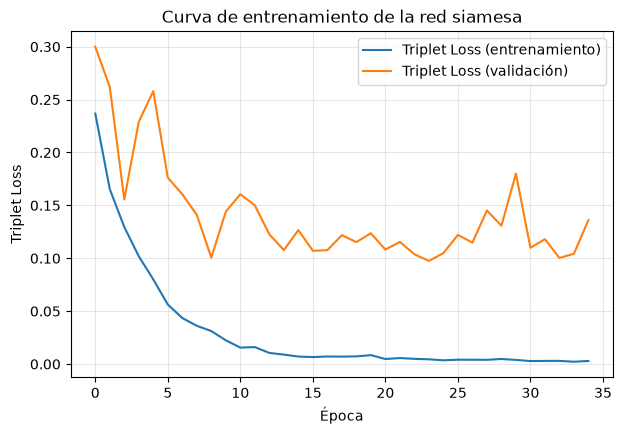

In [9]:
plt.figure(figsize=(7, 4.5))
plt.plot(historial.history["loss"], label="Triplet Loss (entrenamiento)")
plt.plot(historial.history["val_loss"], label="Triplet Loss (validación)")
plt.title("Curva de entrenamiento de la red siamesa")
plt.xlabel("Época")
plt.ylabel("Triplet Loss")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 8. Evaluación: distancias en pares positivos vs. negativos

In [10]:
emb_ancla_test = red_embedding.predict(A_test, verbose=0)
emb_pos_test = red_embedding.predict(P_test, verbose=0)
emb_neg_test = red_embedding.predict(N_test, verbose=0)

dist_pos = np.sum((emb_ancla_test - emb_pos_test) ** 2, axis=1)
dist_neg = np.sum((emb_ancla_test - emb_neg_test) ** 2, axis=1)

print(f"Distancia promedio (mismo rostro)     : {dist_pos.mean():.4f}")
print(f"Distancia promedio (rostros distintos) : {dist_neg.mean():.4f}")

umbral = (dist_pos.mean() + dist_neg.mean()) / 2
aciertos_pos = (dist_pos < umbral).sum()
aciertos_neg = (dist_neg >= umbral).sum()
precision_verificacion = (aciertos_pos + aciertos_neg) / (len(dist_pos) + len(dist_neg))

print(f"Umbral de decisión: {umbral:.4f}")
print(f"Precisión de verificación: {precision_verificacion:.4f}")

Distancia promedio (mismo rostro)     : 0.7410
Distancia promedio (rostros distintos) : 1.5004
Umbral de decisión: 1.1207
Precisión de verificación: 0.7460


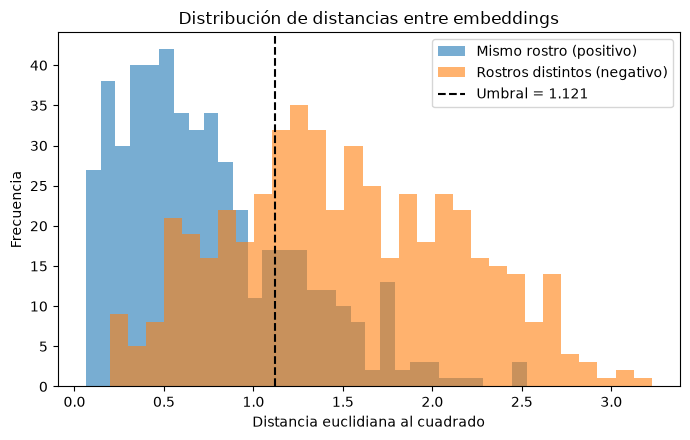

In [11]:
plt.figure(figsize=(7, 4.5))
plt.hist(dist_pos, bins=30, alpha=0.6, label="Mismo rostro (positivo)")
plt.hist(dist_neg, bins=30, alpha=0.6, label="Rostros distintos (negativo)")
plt.axvline(umbral, color="black", linestyle="--", label=f"Umbral = {umbral:.3f}")
plt.title("Distribución de distancias entre embeddings")
plt.xlabel("Distancia euclidiana al cuadrado")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

## 9. One-shot, few-shot y zero-shot learning

Estos tres términos describen cuántos ejemplos necesita un modelo para reconocer algo nuevo:

- **One-shot learning**: reconocer a una persona a partir de una sola foto de referencia, sin reentrenar la red. Es justo lo que se demuestra a continuación.
- **Few-shot learning**: lo mismo, pero con un puñado de fotos de referencia (3-5) por persona en lugar de una sola, lo que normalmente mejora la precisión.
- **Zero-shot learning**: reconocer una categoría de la que el modelo nunca vio ni un solo ejemplo, apoyándose en información indirecta (por ejemplo, una descripción textual) en vez de fotos.

Las redes siamesas con Triplet Loss están pensadas sobre todo para resolver one-shot y few-shot learning: en vez de aprender a clasificar un conjunto cerrado de personas, aprenden una noción general de "qué tan parecidos son dos rostros", aplicable a personas que el modelo nunca vio durante el entrenamiento. A continuación se demuestra el caso one-shot: con una sola foto de referencia, se verifica si el modelo puede reconocer correctamente otra foto de esa misma persona frente a una foto de alguien distinto.

Persona de referencia: Serena Williams
Distancia a otra foto de la MISMA persona : 0.3935
Distancia a foto de OTRA persona           : 1.1005
¿Reconocimiento correcto? Sí


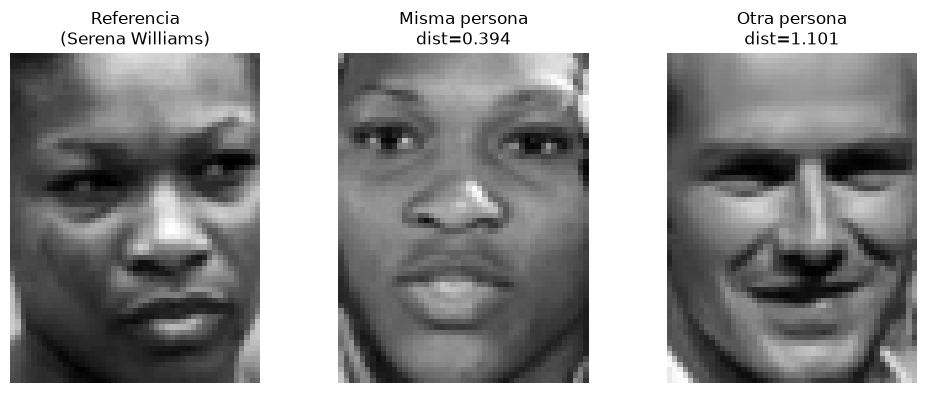

In [12]:
clase_prueba = y_test[0]
idxs_misma_clase = np.where(y_test == clase_prueba)[0]

img_referencia = X_test[idxs_misma_clase[0]]
img_misma_persona = X_test[idxs_misma_clase[1]]
idx_otra_clase = np.where(y_test != clase_prueba)[0][0]
img_otra_persona = X_test[idx_otra_clase]

emb_ref = red_embedding.predict(np.expand_dims(img_referencia, 0), verbose=0)[0]
emb_misma = red_embedding.predict(np.expand_dims(img_misma_persona, 0), verbose=0)[0]
emb_otra = red_embedding.predict(np.expand_dims(img_otra_persona, 0), verbose=0)[0]

dist_misma = np.sum((emb_ref - emb_misma) ** 2)
dist_otra = np.sum((emb_ref - emb_otra) ** 2)

print("Persona de referencia:", nombres[clase_prueba])
print(f"Distancia a otra foto de la MISMA persona : {dist_misma:.4f}")
print(f"Distancia a foto de OTRA persona           : {dist_otra:.4f}")
print("¿Reconocimiento correcto?", "Sí" if dist_misma < dist_otra else "No")

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(img_referencia.squeeze(), cmap="gray"); axes[0].set_title("Referencia\n(" + nombres[clase_prueba] + ")"); axes[0].axis("off")
axes[1].imshow(img_misma_persona.squeeze(), cmap="gray"); axes[1].set_title(f"Misma persona\ndist={dist_misma:.3f}"); axes[1].axis("off")
axes[2].imshow(img_otra_persona.squeeze(), cmap="gray"); axes[2].set_title(f"Otra persona\ndist={dist_otra:.3f}"); axes[2].axis("off")
plt.tight_layout()
plt.show()

## 10. Conclusiones

- La red siamesa aprendió, a partir únicamente de tripletas (ancla, positivo, negativo), a producir embeddings donde dos fotos de la misma persona quedan más cerca entre sí que dos fotos de personas distintas.
- El Triplet Loss no necesita que el modelo clasifique directamente entre un número fijo de personas: aprende una noción general de "similitud facial" que se puede aplicar a personas que el modelo nunca vio durante el entrenamiento, lo que es la base del one-shot learning.
- Esta misma arquitectura, cambiando solo el dataset de entrada, podría aplicarse directamente a un caso con fotos propias o de personas con consentimiento, como originalmente sugiere la actividad.